<a href="https://colab.research.google.com/github/afif-af/Natural-Language-Processing/blob/main/Build_a_Large_Language_Model_by_Sebastian_Raschka.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Chapter 06

#Chapter 07

#Appendix A

#Appendix B

#Appendix C

#Appendix D

#Chapter 02

In [506]:
import urllib.request
url =("https://raw.githubusercontent.com/rasbt/"
      "LLMs-from-scratch/main/ch02/01_main-chapter-code/"
      "the-verdict.txt")
file_path ="the-verdict.txt"
urllib.request.urlretrieve(url, file_path)

('the-verdict.txt', <http.client.HTTPMessage at 0x7efd1ddfe390>)

In [507]:
with open("the-verdict.txt", "r", encoding="utf-8") as f:
  raw_text =f.read()
print("Total number of character :", len(raw_text))
print(raw_text[:99])

Total number of character : 20479
I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no 


In [508]:
import re
text ="Hello, World. This, is a test."
result =re.split(r'(\s)', text)
print(result)

['Hello,', ' ', 'World.', ' ', 'This,', ' ', 'is', ' ', 'a', ' ', 'test.']


In [509]:
result =re.split(r'([,.]|\s)', text)
print(result)

['Hello', ',', '', ' ', 'World', '.', '', ' ', 'This', ',', '', ' ', 'is', ' ', 'a', ' ', 'test', '.', '']


In [510]:
result =[item for item in result if item.strip()]
print(result)

['Hello', ',', 'World', '.', 'This', ',', 'is', 'a', 'test', '.']


In [511]:
text ="Hello, world. Is this-- a test?"
result =re.split(r'([,.:;?_!"()\']|--|\s)', text)
result =[item.strip() for item in result if item.strip()]
print(result)

['Hello', ',', 'world', '.', 'Is', 'this', '--', 'a', 'test', '?']


In [512]:
preprocessed =re.split(r'([,.:;?_!"()\']|--|\s)', raw_text)
preprocessed =[item.strip() for item in preprocessed if item.strip()]
print(len(preprocessed))


4690


In [513]:
print(preprocessed[:30])

['I', 'HAD', 'always', 'thought', 'Jack', 'Gisburn', 'rather', 'a', 'cheap', 'genius', '--', 'though', 'a', 'good', 'fellow', 'enough', '--', 'so', 'it', 'was', 'no', 'great', 'surprise', 'to', 'me', 'to', 'hear', 'that', ',', 'in']


In [514]:
all_words =sorted(set(preprocessed))
vocab_size =len(all_words)
print(vocab_size)

1130


In [515]:
vocab ={token: integer for integer, token in enumerate (all_words)}
for i, item in enumerate (vocab.items()):
  print(item)
  if i>=50:
    break

('!', 0)
('"', 1)
("'", 2)
('(', 3)
(')', 4)
(',', 5)
('--', 6)
('.', 7)
(':', 8)
(';', 9)
('?', 10)
('A', 11)
('Ah', 12)
('Among', 13)
('And', 14)
('Are', 15)
('Arrt', 16)
('As', 17)
('At', 18)
('Be', 19)
('Begin', 20)
('Burlington', 21)
('But', 22)
('By', 23)
('Carlo', 24)
('Chicago', 25)
('Claude', 26)
('Come', 27)
('Croft', 28)
('Destroyed', 29)
('Devonshire', 30)
('Don', 31)
('Dubarry', 32)
('Emperors', 33)
('Florence', 34)
('For', 35)
('Gallery', 36)
('Gideon', 37)
('Gisburn', 38)
('Gisburns', 39)
('Grafton', 40)
('Greek', 41)
('Grindle', 42)
('Grindles', 43)
('HAD', 44)
('Had', 45)
('Hang', 46)
('Has', 47)
('He', 48)
('Her', 49)
('Hermia', 50)


In [516]:
class SimpleTokenizerV1:
  def __init__(self, vocab):
    self.str_to_int =vocab
    self.int_to_str ={i:s for s, i in vocab.items()}

  def encode(self, text):
    preprocessed =re.split(r'([,.?_!"()\']|--|\s)', text)
    preprocessed =[
        item.strip() for item in preprocessed if item.strip()
    ]
    ids =[self.str_to_int[s] for s in preprocessed]
    return ids

  def decode(self, ids):
    text =" ".join([self.int_to_str[i] for i in ids])
    text =re.sub(r'\s+([,.?!"()\'])', r'\1', text)
    return text

In [517]:
tokenizer =SimpleTokenizerV1(vocab)
text =""""It's the last he painted, you know,"
         Mrs. Gisburn said with pardonable pride."""
ids  =tokenizer.encode(text)
print(ids)

[1, 56, 2, 850, 988, 602, 533, 746, 5, 1126, 596, 5, 1, 67, 7, 38, 851, 1108, 754, 793, 7]


In [518]:
print(tokenizer.decode(ids))

" It' s the last he painted, you know," Mrs. Gisburn said with pardonable pride.


In [519]:
# text ="Hello, do you like tea?"
# print(tokenizer.encode(text))                    problem Hello was not use in The Verdict story


In [520]:
all_tokens =sorted(list(set(preprocessed)))
all_tokens.extend(["<|endoftext|>", "<|unk|>"])
vocab ={token:integer for integer, token in enumerate(all_tokens)}
print(len(vocab.items()))

1132


In [521]:
for i, item in enumerate(list(vocab.items())[-5:]):
  print(item)

('younger', 1127)
('your', 1128)
('yourself', 1129)
('<|endoftext|>', 1130)
('<|unk|>', 1131)


In [522]:
class SimpleTokenizerV2:
  def __init__(self, vocab):
    self.str_to_int =vocab
    self.int_to_str ={ i:s for s, i in vocab.items()}

  def encode(self, text):
    preprocessed =re.split(r'([,.:;?_!"()\']|--|\s)', text)
    preprocessed =[
        item.strip() for item in preprocessed if item.strip()
    ]
    preprocessed =[item if item in self.str_to_int
                        else "<|unk|>" for item in preprocessed]
    ids =[self.str_to_int[s] for s in preprocessed]
    return ids

  def decode(self, ids):
    text =" ".join([self.int_to_str[i] for i in ids])
    text =re.sub(r'\s+([,.?;:!"()\\])', r'\1', text)
    return text

In [523]:
text1 = "Hello, do you like tea?"
text2 = "In the sunlit terraces of the palace."

In [524]:
text  =" <|endoftext|> ".join((text1, text2))
print(text)

Hello, do you like tea? <|endoftext|> In the sunlit terraces of the palace.


In [525]:
tokenizer =SimpleTokenizerV2(vocab)
print(tokenizer.encode(text))

[1131, 5, 355, 1126, 628, 975, 10, 1130, 55, 988, 956, 984, 722, 988, 1131, 7]


In [526]:
print(tokenizer.decode(tokenizer.encode(text)))

<|unk|>, do you like tea? <|endoftext|> In the sunlit terraces of the <|unk|>.


In [527]:
from importlib.metadata import version
import tiktoken
print("tiktoken version:", version("tiktoken"))

tiktoken version: 0.13.0


In [528]:
tokenizer =tiktoken.get_encoding("gpt2")


In [529]:
text =(
    "Hello, do you like tea? <|endoftext|> In the sunlit terraces of someunknownPlace"

)
integers =tokenizer.encode(text, allowed_special={"<|endoftext|>"})
print(integers)

[15496, 11, 466, 345, 588, 8887, 30, 220, 50256, 554, 262, 4252, 18250, 8812, 2114, 286, 617, 34680, 27271]


In [530]:
strings =tokenizer.decode(integers)
print(strings)

Hello, do you like tea? <|endoftext|> In the sunlit terraces of someunknownPlace


In [531]:
with open("the-verdict.txt", "r", encoding="utf-8") as f:
  raw_text =f.read()

enc_text =tokenizer.encode(raw_text)
print(len(enc_text))


5145


In [532]:
enc_sample =enc_text[50:]


In [533]:
context_size =4
x =enc_sample[:context_size]
y =enc_sample[1:context_size+1]
print(f"x: {x}")
print(f"y:      {y}")

x: [290, 4920, 2241, 287]
y:      [4920, 2241, 287, 257]


In [534]:
for i in range(1, context_size+1):
  context =enc_sample[:i]
  desired =enc_sample[i]
  print(context, "---->",desired)


[290] ----> 4920
[290, 4920] ----> 2241
[290, 4920, 2241] ----> 287
[290, 4920, 2241, 287] ----> 257


In [535]:
for i in range(1, context_size +1):
  context =enc_sample[:i]
  desired =enc_sample[i]
  print(tokenizer.decode(context), "---->", tokenizer.decode([desired]))

 and ---->  established
 and established ---->  himself
 and established himself ---->  in
 and established himself in ---->  a


In [536]:
import torch
from torch.utils.data import Dataset, DataLoader

In [537]:
class GPTDatasetV1(Dataset):
  def __init__(self, txt, tokenzier, max_length, stride):
    self.input_ids =[]
    self.target_ids =[]

    token_ids =tokenizer.encode(txt)

    for i in range(0, len(token_ids) -max_length, stride):
      input_chunk  =token_ids[i:   i+max_length]
      target_chunk =token_ids[i+1: i+max_length +1]
      self.input_ids.append(torch.tensor(input_chunk))
      self.target_ids.append(torch.tensor(target_chunk))

  def __len__(self):
    return len(self.input_ids)

  def __getitem__(self, idx):
    return self.input_ids[idx], self.target_ids[idx]

In [538]:
def create_dataloader_v1 (txt, batch_size=4, max_length=256,
                          stride=128, shuffle=True, drop_last=True,
                          num_workers=0):
  tokenizer =tiktoken.get_encoding("gpt2")
  dataset   =GPTDatasetV1(txt, tokenizer, max_length, stride)
  dataloader =DataLoader(
      dataset,
      batch_size  =batch_size,
      shuffle     =shuffle,
      drop_last   =drop_last,
      num_workers =num_workers

  )
  return dataloader



In [539]:
with open("the-verdict.txt", "r", encoding="utf-8") as f:
  raw_text  = f.read()

dataloader  =create_dataloader_v1(
    raw_text, batch_size=1, max_length=4, stride=1, shuffle=False
)
data_iter   =iter(dataloader)
first_batch =next(data_iter)
print(first_batch)

[tensor([[  40,  367, 2885, 1464]]), tensor([[ 367, 2885, 1464, 1807]])]


In [540]:
second_batch =next(data_iter)
print(second_batch)

[tensor([[ 367, 2885, 1464, 1807]]), tensor([[2885, 1464, 1807, 3619]])]


In [541]:
dataloader =create_dataloader_v1(
    raw_text, batch_size=8, max_length =4,stride=4,
    shuffle=False
)

In [542]:
data_iter =iter(dataloader)
inputs, targets =next(data_iter)
print("Inputs:\n",    inputs)
print("\nTargets:\n", targets)

Inputs:
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Targets:
 tensor([[  367,  2885,  1464,  1807],
        [ 3619,   402,   271, 10899],
        [ 2138,   257,  7026, 15632],
        [  438,  2016,   257,   922],
        [ 5891,  1576,   438,   568],
        [  340,   373,   645,  1049],
        [ 5975,   284,   502,   284],
        [ 3285,   326,    11,   287]])


In [543]:
input_ids =torch.tensor([2,3, 5,1])


In [544]:
vocab_size=6
output_dim =3


In [545]:
torch.manual_seed(123)
embedding_layer =torch.nn.Embedding(vocab_size, output_dim)
print(embedding_layer)

Embedding(6, 3)


In [546]:
print(embedding_layer(torch.tensor([3])))


tensor([[-0.4015,  0.9666, -1.1481]], grad_fn=<EmbeddingBackward0>)


In [547]:
print(embedding_layer(input_ids))

tensor([[ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-2.8400, -0.7849, -1.4096],
        [ 0.9178,  1.5810,  1.3010]], grad_fn=<EmbeddingBackward0>)


In [548]:
vocab_size  =50257
output_dim =256
token_embedding_layer =torch.nn.Embedding(vocab_size, output_dim)

In [549]:
max_length =4
dataloader =create_dataloader_v1(
    raw_text, batch_size=8, max_length=max_length, stride=max_length, shuffle=False,
)
data_iter =iter(dataloader)
inputs, targets =next(data_iter)
print("Token IDs: \n", inputs)
print("\nInputs shape: \n", inputs.shape)

Token IDs: 
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Inputs shape: 
 torch.Size([8, 4])


In [550]:
token_embeddings =token_embedding_layer(inputs)
print(token_embeddings.shape)

torch.Size([8, 4, 256])


In [551]:
token_embeddings

tensor([[[ 0.4913,  1.1239,  1.4588,  ..., -0.3995, -1.8735, -0.1445],
         [ 0.4481,  0.2536, -0.2655,  ...,  0.4997, -1.1991, -1.1844],
         [-0.2507, -0.0546,  0.6687,  ...,  0.9618,  2.3737, -0.0528],
         [ 0.9457,  0.8657,  1.6191,  ..., -0.4544, -0.7460,  0.3483]],

        [[ 1.5460,  1.7368, -0.7848,  ..., -0.1004,  0.8584, -0.3421],
         [-1.8622, -0.1914, -0.3812,  ...,  1.1220, -0.3496,  0.6091],
         [ 1.9847, -0.6483, -0.1415,  ..., -0.3841, -0.9355,  1.4478],
         [ 0.9647,  1.2974, -1.6207,  ...,  1.1463,  1.5797,  0.3969]],

        [[-0.7713,  0.6572,  0.1663,  ..., -0.8044,  0.0542,  0.7426],
         [ 0.8046,  0.5047,  1.2922,  ...,  1.4648,  0.4097,  0.3205],
         [ 0.0795, -1.7636,  0.5750,  ...,  2.1823,  1.8231, -0.3635],
         [ 0.4267, -0.0647,  0.5686,  ..., -0.5209,  1.3065,  0.8473]],

        ...,

        [[-1.6156,  0.9610, -2.6437,  ..., -0.9645,  1.0888,  1.6383],
         [-0.3985, -0.9235, -1.3163,  ..., -1.1582, -1.13

In [552]:
context_length =max_length
pos_embedding_layer =torch.nn.Embedding(context_length, output_dim)
pos_embeddings      =pos_embedding_layer(torch.arange(context_length))
print(pos_embeddings.shape)

torch.Size([4, 256])


In [553]:
input_embeddings =token_embeddings +pos_embeddings
print(input_embeddings.shape)

torch.Size([8, 4, 256])


#Chapter 03

In [554]:
import torch
inputs =torch.tensor(
     [[0.43, 0.15, 0.89], # Your (x^1)
      [0.55, 0.87, 0.66], # journey (x^2)
      [0.57, 0.85, 0.64], # starts (x^3)
      [0.22, 0.58, 0.33], # with (x^4)
      [0.77, 0.25, 0.10], # one (x^5)
      [0.05, 0.80, 0.55]] # step (x^6)
)

In [555]:
inputs.shape

torch.Size([6, 3])

In [556]:
query         =inputs[1]
attn_scores_2 =torch.empty(inputs.shape[0])
for i, x_i in enumerate(inputs):
  attn_scores_2[i] =torch.dot(x_i, query)
print(attn_scores_2)

tensor([0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865])


In [557]:
attn_weights_2_tmp =attn_scores_2 / attn_scores_2.sum()
print("Attention weights:", attn_weights_2_tmp)
print("Sum:", attn_weights_2_tmp.sum())

Attention weights: tensor([0.1455, 0.2278, 0.2249, 0.1285, 0.1077, 0.1656])
Sum: tensor(1.0000)


In [558]:
def softmax_naive(x):
  return torch.exp(x) /torch.exp(x).sum(dim=0)

attn_weight_2_naive =softmax_naive(attn_scores_2)
print("Attention weights:", attn_weight_2_naive)
print("Sum:", attn_weight_2_naive.sum())

Attention weights: tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
Sum: tensor(1.)


In [559]:
attn_weights_2 =torch.softmax(attn_scores_2, dim=0)
print("Attention weights:", attn_weights_2)
print("Sum:", attn_weights_2.sum())

Attention weights: tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
Sum: tensor(1.)


In [560]:
query            =inputs[1]
context_vec_2    =torch.zeros(query.shape)
for i, x_i in enumerate(inputs):
  context_vec_2 +=attn_weights_2[i] * x_i
print(context_vec_2)

tensor([0.4419, 0.6515, 0.5683])


In [561]:
attn_scores =torch.empty(6,6)
for i, x_i in enumerate(inputs):
  for j, x_j in enumerate(inputs):
    attn_scores[i, j] =torch.dot(x_i,x_j)
print(attn_scores)

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


In [562]:
attn_scores=inputs @ inputs.T
print(attn_scores)

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


In [563]:
attn_weights =torch.softmax(attn_scores, dim =-1)
print(attn_weights)

tensor([[0.2098, 0.2006, 0.1981, 0.1242, 0.1220, 0.1452],
        [0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581],
        [0.1390, 0.2369, 0.2326, 0.1242, 0.1108, 0.1565],
        [0.1435, 0.2074, 0.2046, 0.1462, 0.1263, 0.1720],
        [0.1526, 0.1958, 0.1975, 0.1367, 0.1879, 0.1295],
        [0.1385, 0.2184, 0.2128, 0.1420, 0.0988, 0.1896]])


In [564]:
row_2_sum =sum([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
print("Row 2 sum:", row_2_sum)
print("All row sums: ", attn_weights.sum(dim=-1))

Row 2 sum: 1.0
All row sums:  tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


In [565]:
all_context_vecs =attn_weights @inputs
print(all_context_vecs)

tensor([[0.4421, 0.5931, 0.5790],
        [0.4419, 0.6515, 0.5683],
        [0.4431, 0.6496, 0.5671],
        [0.4304, 0.6298, 0.5510],
        [0.4671, 0.5910, 0.5266],
        [0.4177, 0.6503, 0.5645]])


In [566]:
print("Previous 2nd context vector: ", context_vec_2)

Previous 2nd context vector:  tensor([0.4419, 0.6515, 0.5683])


In [567]:
x_2 =inputs[1]
d_in =inputs.shape[1]
d_out=2


In [568]:
torch.manual_seed(123)
W_query =torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_key   =torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_value =torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)

In [569]:
query_2 =x_2 @ W_query
key_2   =x_2 @ W_key
value_2 =x_2 @ W_value
print(value_2)

tensor([0.3951, 1.0037])


In [570]:
keys   =inputs @ W_key
values =inputs @ W_value

print("Keys shape:", keys.shape)
print("values shape:", values.shape)

Keys shape: torch.Size([6, 2])
values shape: torch.Size([6, 2])


In [571]:
keys_2        =keys[1]
attn_score_22 =query_2.dot(keys_2)
print(attn_score_22)

tensor(1.8524)


In [572]:
attn_scores_2 =query_2 @keys.T
print(attn_scores_2)

tensor([1.2705, 1.8524, 1.8111, 1.0795, 0.5577, 1.5440])


In [573]:
d_k            =keys.shape[-1]
attn_weights_2 =torch.softmax(attn_scores_2 /d_k **0.55 , dim =-1)
print(attn_weights_2)

tensor([0.1508, 0.2244, 0.2181, 0.1323, 0.0927, 0.1817])


In [574]:
context_vec_2 =attn_weights_2 @ values
print(context_vec_2)

tensor([0.3053, 0.8191])


In [575]:
import torch.nn as nn
class SelfAttention_v1(nn.Module):
  def __init__(self, d_in, d_out):
    super().__init__()
    self.W_query  =nn.Parameter(torch.rand(d_in, d_out))
    self.W_key    =nn.Parameter(torch.rand(d_in, d_out))
    self.W_value  =nn.Parameter(torch.rand(d_in, d_out))

  def forward(self, x):
    keys    = x @ self.W_key
    queries = x @ self.W_query
    values  = x @ self.W_value
    attn_scores  = queries @ keys.T
    attn_weights = torch.softmax(
        attn_scores / (keys.shape [-1]**0.5), dim=-1
    )
    context_vec = attn_weights @ values
    return context_vec

In [576]:
torch.manual_seed(123)
sa_v1 = SelfAttention_v1(d_in, d_out)
print(sa_v1(inputs))

tensor([[0.2996, 0.8053],
        [0.3061, 0.8210],
        [0.3058, 0.8203],
        [0.2948, 0.7939],
        [0.2927, 0.7891],
        [0.2990, 0.8040]], grad_fn=<MmBackward0>)


In [577]:
class SelfAttention_v2(nn.Module):
  def __init__(self, d_in, d_out, qkv_bias=False):
    super().__init__()
    self.W_query =nn.Linear(d_in, d_out, bias =qkv_bias)
    self.W_key   =nn.Linear(d_in, d_out, bias =qkv_bias)
    self.W_value =nn.Linear(d_in, d_out, bias =qkv_bias)

  def forward(self, x):
    keys    =self.W_key(x)
    queries =self.W_query(x)
    values  =self.W_value(x)
    attn_scores =queries @ keys.T
    attn_weights =torch.softmax(
        attn_scores/(keys.shape[-1] **0.5 ), dim =-1
    )
    context_vec =attn_weights @ values
    return context_vec



In [578]:
torch.manual_seed(789)
sa_v2 =SelfAttention_v2(d_in, d_out)
print(sa_v2(inputs))

tensor([[-0.0739,  0.0713],
        [-0.0748,  0.0703],
        [-0.0749,  0.0702],
        [-0.0760,  0.0685],
        [-0.0763,  0.0679],
        [-0.0754,  0.0693]], grad_fn=<MmBackward0>)


In [579]:
queries =sa_v2.W_query(inputs)
keys    =sa_v2.W_key(inputs)
attn_scores =queries @ keys.T
attn_weights =torch.softmax(attn_scores / (keys.shape[-1] **0.5), dim=-1)
print(attn_weights)

tensor([[0.1921, 0.1646, 0.1652, 0.1550, 0.1721, 0.1510],
        [0.2041, 0.1659, 0.1662, 0.1496, 0.1665, 0.1477],
        [0.2036, 0.1659, 0.1662, 0.1498, 0.1664, 0.1480],
        [0.1869, 0.1667, 0.1668, 0.1571, 0.1661, 0.1564],
        [0.1830, 0.1669, 0.1670, 0.1588, 0.1658, 0.1585],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<SoftmaxBackward0>)


In [580]:
context_length  =attn_scores.shape[0]
mask_simple     =torch.tril(torch.ones(context_length, context_length))
print(mask_simple)


tensor([[1., 0., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0., 0.],
        [1., 1., 1., 0., 0., 0.],
        [1., 1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1., 1.]])


In [581]:
masked_simple =attn_weights *mask_simple
print(masked_simple)

tensor([[0.1921, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2041, 0.1659, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2036, 0.1659, 0.1662, 0.0000, 0.0000, 0.0000],
        [0.1869, 0.1667, 0.1668, 0.1571, 0.0000, 0.0000],
        [0.1830, 0.1669, 0.1670, 0.1588, 0.1658, 0.0000],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<MulBackward0>)


In [582]:
row_sums           =masked_simple.sum(dim=-1, keepdim=True)
masked_simple_norm =masked_simple / row_sums
print(masked_simple_norm)



tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5517, 0.4483, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3800, 0.3097, 0.3103, 0.0000, 0.0000, 0.0000],
        [0.2758, 0.2460, 0.2462, 0.2319, 0.0000, 0.0000],
        [0.2175, 0.1983, 0.1984, 0.1888, 0.1971, 0.0000],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<DivBackward0>)


In [583]:
mask = torch.triu(torch.ones(context_length, context_length), diagonal =1)
masked =attn_scores.masked_fill(mask.bool(), -torch.inf)
print(masked)

tensor([[0.2899,   -inf,   -inf,   -inf,   -inf,   -inf],
        [0.4656, 0.1723,   -inf,   -inf,   -inf,   -inf],
        [0.4594, 0.1703, 0.1731,   -inf,   -inf,   -inf],
        [0.2642, 0.1024, 0.1036, 0.0186,   -inf,   -inf],
        [0.2183, 0.0874, 0.0882, 0.0177, 0.0786,   -inf],
        [0.3408, 0.1270, 0.1290, 0.0198, 0.1290, 0.0078]],
       grad_fn=<MaskedFillBackward0>)


In [584]:
attn_weights =torch.softmax(masked / (keys.shape[-1] **0.5), dim =1)
print(attn_weights)

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5517, 0.4483, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3800, 0.3097, 0.3103, 0.0000, 0.0000, 0.0000],
        [0.2758, 0.2460, 0.2462, 0.2319, 0.0000, 0.0000],
        [0.2175, 0.1983, 0.1984, 0.1888, 0.1971, 0.0000],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<SoftmaxBackward0>)


In [585]:
torch.manual_seed(123)
dropout =torch.nn.Dropout(0.5)
example =torch.ones(6,6)
print(dropout(example))

tensor([[2., 2., 0., 2., 2., 0.],
        [0., 0., 0., 2., 0., 2.],
        [2., 2., 2., 2., 0., 2.],
        [0., 2., 2., 0., 0., 2.],
        [0., 2., 0., 2., 0., 2.],
        [0., 2., 2., 2., 2., 0.]])


In [586]:
torch.manual_seed(123)
print(dropout(attn_weights))

tensor([[2.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.7599, 0.6194, 0.6206, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.4921, 0.4925, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.3966, 0.0000, 0.3775, 0.0000, 0.0000],
        [0.0000, 0.3327, 0.3331, 0.3084, 0.3331, 0.0000]],
       grad_fn=<MulBackward0>)


In [587]:
batch =torch.stack((inputs, inputs), dim=0)
print(batch.shape)

torch.Size([2, 6, 3])


In [588]:
class CausalAttention(nn.Module):
  def __init__(self, d_in, d_out, context_length, dropout, qkv_bias =False):
    super().__init__()
    self.d_out =d_out
    self.W_query =nn.Linear(d_in, d_out, bias =qkv_bias)
    self.W_key   =nn.Linear(d_in, d_out, bias =qkv_bias)
    self.W_value =nn.Linear(d_in, d_out, bias =qkv_bias)
    self.dropout =nn.Dropout(dropout)
    self.register_buffer(
        'mask',
        torch.triu(torch.ones(context_length, context_length),
                   diagonal=1)
    )

  def forward(self, x):
    b, num_tokens, d_in =x.shape
    keys =self.W_key(x)
    queries =self.W_query(x)
    values =self.W_value(x) # Corrected typo from 'vlaues'

    attn_scores =queries @ keys.transpose(1, 2)
    attn_scores.masked_fill(
        self.mask.bool()[:num_tokens, :num_tokens], -torch.inf
    )
    attn_weights =torch.softmax(
        attn_scores / (keys.shape[-1] **0.5) , dim =-1
    )
    attn_weights =self.dropout(attn_weights)
    context_vec =attn_weights @ values
    return context_vec

In [589]:
torch.manual_seed(123)
context_length =batch.shape[1]
ca =CausalAttention(d_in, d_out, context_length, 0.0)
context_vecs =ca(batch)
print("Context_vecs.shape:", context_vecs.shape)


Context_vecs.shape: torch.Size([2, 6, 2])


In [590]:
class MultiHeadAttentionWrapper(nn.Module):
  def __init__(self,d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
    super().__init__()
    self.heads =nn.ModuleList(
        [CausalAttention(
            d_in, d_out, context_length, dropout, qkv_bias
        )for _ in range(num_heads)]
    )

  def forward(self, x):
    return torch.cat([head(x) for head in self.heads], dim=-1)

In [591]:
torch.manual_seed(123)
context_length =batch.shape[1]
d_in, d_out = 3, 2
mha =MultiHeadAttentionWrapper(
    d_in, d_out, context_length, 0.0, num_heads =2
)
context_vecs =mha(batch)
print(context_vecs)
print("context_vecs.shape:", context_vecs.shape
      )

tensor([[[-0.5337, -0.1051,  0.5085,  0.3508],
         [-0.5323, -0.1080,  0.5084,  0.3508],
         [-0.5323, -0.1079,  0.5084,  0.3506],
         [-0.5297, -0.1076,  0.5074,  0.3471],
         [-0.5311, -0.1066,  0.5076,  0.3446],
         [-0.5299, -0.1081,  0.5077,  0.3493]],

        [[-0.5337, -0.1051,  0.5085,  0.3508],
         [-0.5323, -0.1080,  0.5084,  0.3508],
         [-0.5323, -0.1079,  0.5084,  0.3506],
         [-0.5297, -0.1076,  0.5074,  0.3471],
         [-0.5311, -0.1066,  0.5076,  0.3446],
         [-0.5299, -0.1081,  0.5077,  0.3493]]], grad_fn=<CatBackward0>)
context_vecs.shape: torch.Size([2, 6, 4])


In [592]:
class MultiHeadAttention(nn.Module):
  def __init__(self,d_in,d_out, context_length, dropout, num_heads, qkv_bias=False):
    super().__init__()
    assert (d_out % num_heads ==0), \
           "d_out must be divisible by num_heads"

    self.d_out =d_out
    self.num_heads =num_heads
    self.head_dim  =d_out// num_heads
    self.W_query   =nn.Linear(d_in, d_out, bias=qkv_bias)
    self.W_key     =nn.Linear(d_in, d_out, bias =qkv_bias)
    self.W_values  =nn.Linear(d_in, d_out, bias =qkv_bias)
    self.out_proj  =nn.Linear(d_out, d_out)
    self.dropout   =nn.Dropout(dropout)
    self.register_buffer(
        "mask",
        torch.triu(torch.ones(context_length, context_length),
                   diagonal=1)
    )
  def forward(self, x):
    b, num_tokens, d_in =x.shape
    keys     =self.W_key(x)
    queries  =self.W_query(x)
    values   =self.W_values(x)

    keys      =keys.view(b, num_tokens, self.num_heads, self.head_dim)
    values    =values.view(b, num_tokens, self.num_heads, self.head_dim)
    queries   =queries.view(
        b, num_tokens, self.num_heads, self.head_dim
    )

    keys       =keys.transpose(1,2)
    queries    =queries.transpose(1,2)
    values     =values.transpose(1,2)

    attn_scores =queries @ keys.transpose(2,3)
    mask_bool   =self.mask.bool()[:num_tokens, :num_tokens]

    attn_scores.masked_fill_(mask_bool, -torch.inf)

    attn_weights =torch.softmax(
        attn_scores / (keys.shape[-1] **0.5), dim =-1
    )

    attn_weights =self.dropout(attn_weights)

    context_vec  =(attn_weights @ values).transpose(1,2)

    context_vec  =context_vec.contiguous().view(
        b, num_tokens, self.d_out
    )
    context_vec      =self.out_proj(context_vec)
    return context_vec

In [593]:

a = torch.tensor([[[[0.2745, 0.6584, 0.2775, 0.8573],
                    [0.8993, 0.0390, 0.9268, 0.7388],
                    [0.7179, 0.7058, 0.9156, 0.4340]],

                    [[0.0772, 0.3565, 0.1479, 0.5331],
                    [0.4066, 0.2318, 0.4545, 0.9737],
                    [0.4606, 0.5159, 0.4220, 0.5786]]]])

In [594]:
print(a @ a.transpose(2,3))

tensor([[[[1.3208, 1.1631, 1.2879],
          [1.1631, 2.2150, 1.8424],
          [1.2879, 1.8424, 2.0402]],

         [[0.4391, 0.7003, 0.5903],
          [0.7003, 1.3737, 1.0620],
          [0.5903, 1.0620, 0.9912]]]])


In [595]:
first_head =a[0, 0, :, :]
first_res  =first_head @ first_head.T
print("First head: \n", first_res)

second_head =a[0, 1, :, :]
second_res =second_head @ second_head.T
print("Second head:\n", second_res)

First head: 
 tensor([[1.3208, 1.1631, 1.2879],
        [1.1631, 2.2150, 1.8424],
        [1.2879, 1.8424, 2.0402]])
Second head:
 tensor([[0.4391, 0.7003, 0.5903],
        [0.7003, 1.3737, 1.0620],
        [0.5903, 1.0620, 0.9912]])


In [596]:
torch.manual_seed(123)
batch_size, context_length, d_in=batch.shape
d_out=2
mha=MultiHeadAttention(d_in, d_out, context_length, 0.0, num_heads=2)
context_vecs =mha(batch)
print(context_vecs)
print("context_vecs.shape:", context_vecs.shape)

tensor([[[0.3190, 0.4858],
         [0.2943, 0.3897],
         [0.2856, 0.3593],
         [0.2693, 0.3873],
         [0.2639, 0.3928],
         [0.2575, 0.4028]],

        [[0.3190, 0.4858],
         [0.2943, 0.3897],
         [0.2856, 0.3593],
         [0.2693, 0.3873],
         [0.2639, 0.3928],
         [0.2575, 0.4028]]], grad_fn=<ViewBackward0>)
context_vecs.shape: torch.Size([2, 6, 2])


#Chapter 04

In [597]:
GPT_CONFIG_124M ={
    "vocab_size"    : 50257,
    "context_length": 1024,
    "emb_dim"       : 768,
    "n_heads"       : 12,
    "n_layers"      : 12,
    "drop_rate"     : 0.1,
    "qkv_bias"      : False
}

In [598]:
import torch
import torch.nn as nn

class DummyGPTModel(nn.Module):
  def __init__(self, cfg):
    super().__init__()
    self.tok_emb =nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
    self.pos_emb =nn.Embedding(cfg["context_length"], cfg["emb_dim"])
    self.drop_emb=nn.Dropout(cfg["drop_rate"])
    self.trf_blocks=nn.Sequential(
        *[DummyTransformerBlock(cfg)
          for _ in range(cfg["n_layers"])]
    )
    self.final_norm =DummyLayerNorm(cfg["emb_dim"])
    self.out_head   =nn.Linear(
        cfg["emb_dim"], cfg["vocab_size"], bias=False
    )

  def forward(self, in_idx):
    batch_size, seq_len =in_idx.shape
    tok_embeds          =self.tok_emb(in_idx)
    pos_embeds          =self.pos_emb(
        torch.arange(seq_len, device =in_idx.device)
    )
    x =tok_embeds + pos_embeds
    x =self.drop_emb(x)
    x =self.trf_blocks(x)
    x =self.final_norm(x)
    logits =self.out_head(x)
    return logits

In [599]:
class DummyTransformerBlock(nn.Module):
  def __init__(self, cfg):
    super().__init__()

  def forward(self, x):
    return x

class DummyLayerNorm(nn.Module):
  def __init__(self, normalized_shape, eps =1e-5):
    super().__init__()

  def forward(self, x):
    return x

In [600]:
import tiktoken
tokenizer =tiktoken.get_encoding("gpt2")
batch=[]
txt1 ="Every effort moves you"
txt2 ="Every day hold a"

batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
batch =torch.stack(batch, dim =0)
print(batch)

tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 1745,  257]])


In [601]:
torch.manual_seed(123)
model =DummyGPTModel(GPT_CONFIG_124M)
logits =model(batch)
print("Output shape:", logits.shape)
print(logits)

Output shape: torch.Size([2, 4, 50257])
tensor([[[-1.2034,  0.3201, -0.7130,  ..., -1.5548, -0.2390, -0.4667],
         [-0.1192,  0.4539, -0.4432,  ...,  0.2392,  1.3469,  1.2430],
         [ 0.5307,  1.6720, -0.4695,  ...,  1.1966,  0.0111,  0.5835],
         [ 0.0139,  1.6755, -0.3388,  ...,  1.1586, -0.0435, -1.0400]],

        [[-1.0908,  0.1798, -0.9484,  ..., -1.6047,  0.2439, -0.4530],
         [-0.7860,  0.5581, -0.0610,  ...,  0.4835, -0.0077,  1.6621],
         [ 0.5525,  0.4192, -0.1347,  ...,  0.3754,  0.2626, -0.5079],
         [-0.2407, -0.7349, -0.5102,  ...,  2.0057, -0.3694,  0.1814]]],
       grad_fn=<UnsafeViewBackward0>)


In [602]:
torch.manual_seed(123)
batch_example =torch.randn(2, 5)
layer         =nn.Sequential(nn.Linear(5, 6),
                             nn.ReLU())
out           =layer(batch_example)
print(out)


tensor([[0.2260, 0.3470, 0.0000, 0.2216, 0.0000, 0.0000],
        [0.2133, 0.2394, 0.0000, 0.5198, 0.3297, 0.0000]],
       grad_fn=<ReluBackward0>)


In [603]:
mean =out.mean(dim =-1, keepdim =True)
var  =out.var(dim =-1, keepdim =True)
print("Mean:\n",mean)
print("Varience:\n", var)

Mean:
 tensor([[0.1324],
        [0.2170]], grad_fn=<MeanBackward1>)
Varience:
 tensor([[0.0231],
        [0.0398]], grad_fn=<VarBackward0>)


In [604]:
out_norm =(out-mean)/torch.sqrt(var)
mean     =out_norm.mean(dim =-1, keepdim=True)
var      =out_norm.var(dim =-1, keepdim =True)
print("Normalized layer outputs:\n", out_norm)
print("Mean:\n", mean)
print("Variance:\n", var)


Normalized layer outputs:
 tensor([[ 0.6159,  1.4126, -0.8719,  0.5872, -0.8719, -0.8719],
        [-0.0189,  0.1121, -1.0876,  1.5173,  0.5647, -1.0876]],
       grad_fn=<DivBackward0>)
Mean:
 tensor([[0.0000],
        [0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


In [605]:
torch.set_printoptions(sci_mode=False)
print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[0.0000],
        [0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


In [606]:
class LayerNorm(nn.Module):
  def __init__(self, emb_dim):
    super().__init__()
    self.eps   =1e-5
    self.scale =nn.Parameter(torch.ones(emb_dim))
    self.shift =nn.Parameter(torch.zeros(emb_dim))

  def forward(self, x):
    mean  =x.mean(dim =-1, keepdim=True)
    var   =x.var(dim =-1, keepdim=True, unbiased=False)
    norm_x=(x - mean) / torch.sqrt(var + self.eps)
    return self.scale * norm_x + self.shift



In [607]:
ln     =LayerNorm(emb_dim =5)
out_ln =ln(batch_example)
mean   =out_ln.mean(dim=-1, keepdim=True)
var    =out_ln.var(dim=-1, unbiased=False, keepdim=True)
print("Mean:\n", mean)
print("Variance:\n", var)


Mean:
 tensor([[-0.0000],
        [ 0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


In [608]:
class GELU(nn.Module):
  def __init__(self):
    super().__init__()

  def forward(self, x):
    return 0.5 * x *(1 +torch.tanh( torch.sqrt(torch.tensor(2.0/torch.pi)) *
                                   (x +0.44715 * torch.pow(x, 3))))


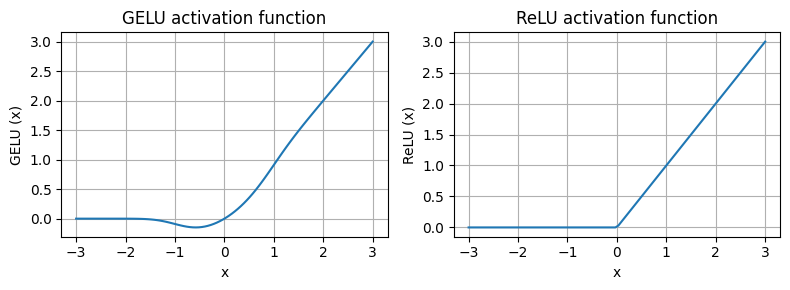

In [609]:
import matplotlib.pyplot as plt
gelu, relu =GELU(), nn.ReLU()

x =torch.linspace(-3, 3, 100)
y_gelu, y_relu =gelu(x), relu(x)
plt.figure(figsize=(8,3))
for i, (y, label) in enumerate(zip([y_gelu, y_relu], ["GELU", "ReLU"]), 1):
  plt.subplot(1,2,i)
  plt.plot(x, y)
  plt.title(f"{label} activation function")
  plt.xlabel("x")
  plt.ylabel(f"{label} (x)")
  plt.grid(True)
plt.tight_layout()
plt.show()


In [610]:
class FeedForward(nn.Module):
  def __init__(self, cfg):
    super().__init__()
    self.layers =nn.Sequential(
        nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),
        GELU(),
        nn.Linear(4*cfg["emb_dim"], cfg["emb_dim"])
    )

  def forward(self, x):
    return self.layers(x)

In [611]:
ffn =FeedForward(GPT_CONFIG_124M)
x   =torch.rand(2, 3, 768)
out =ffn(x)
print(out.shape)

torch.Size([2, 3, 768])


In [612]:
class ExampleDeepNeuralNetwork(nn.Module):
  def __init__(self, layer_sizes, use_shortcut):
    super().__init__()
    self.use_shortcut =use_shortcut
    self.layers =nn.ModuleList([
        nn.Sequential (nn.Linear(layer_sizes[0], layer_sizes[1]),
                       GELU()),
        nn.Sequential (nn.Linear(layer_sizes[1], layer_sizes[2]),
                       GELU()),
        nn.Sequential (nn.Linear(layer_sizes[2], layer_sizes[3]),
                       GELU()),
        nn.Sequential (nn.Linear(layer_sizes[3], layer_sizes[4]),
                       GELU()),
        nn.Sequential (nn.Linear(layer_sizes[4], layer_sizes[5]),
                       GELU()),

    ])

  def forward(self, x):
    for layer in self.layers:
      layer_output =layer(x)
      if self.use_shortcut and x.shape == layer_output.shape:
        x = x + layer_output
      else:
        x = layer_output

    return x

In [613]:
layer_sizes  =[3,3,3,3,3,1]
sample_input =torch.tensor([[1., 0., -1.]])
torch.manual_seed(123)
model_without_shorcut = ExampleDeepNeuralNetwork(
    layer_sizes, use_shortcut=False
)

In [614]:
def print_gradients(model, x):
  output =model(x)
  target =torch.tensor([[0.]])

  loss_fn   =nn.MSELoss()
  loss   =loss_fn(output, target)

  loss.backward()

  for name, param in model.named_parameters():
    if 'weight' in name:
      if param.grad is not None:
        print(f"{name} has gradient mean of {param.grad.abs().mean().item()}")
      else:
        print(f"{name} has no gradient.")

print_gradients(model_without_shorcut, sample_input)

layers.0.0.weight has gradient mean of 0.000204713229322806
layers.1.0.weight has gradient mean of 0.00012317953223828226
layers.2.0.weight has gradient mean of 0.0007344746263697743
layers.3.0.weight has gradient mean of 0.0013871209230273962
layers.4.0.weight has gradient mean of 0.005026495084166527


In [615]:
layer_sizes = [3,3,3,3,3,1]
sample_input = torch.tensor([[1., 0., -1.]])
torch.manual_seed(123)

model_with_shorcut = ExampleDeepNeuralNetwork(
    layer_sizes, use_shortcut=True
)

print_gradients (model_with_shorcut, sample_input)

layers.0.0.weight has gradient mean of 0.29920274019241333
layers.1.0.weight has gradient mean of 0.2749510407447815
layers.2.0.weight has gradient mean of 0.454661101102829
layers.3.0.weight has gradient mean of 0.3629586696624756
layers.4.0.weight has gradient mean of 1.763088583946228


In [616]:
class TransformerBlock(nn.Module):
  def __init__(self, cfg):
    super().__init__()
    self.att =MultiHeadAttention(
        d_in =cfg["emb_dim"],
        d_out=cfg["emb_dim"],
        context_length =cfg["context_length"],
        num_heads =cfg["n_heads"],
        dropout   =cfg["drop_rate"],
        qkv_bias  =cfg["qkv_bias"],

    )
    self.ff =FeedForward(cfg)
    self.norm1= LayerNorm(cfg["emb_dim"])
    self.norm2= LayerNorm(cfg["emb_dim"])
    self.drop_shortcut =nn.Dropout(cfg["drop_rate"])

  def forward(self, x):

    shortcut =x
    x  =self.norm1(x)
    x  =self.att(x)
    x  =self.drop_shortcut(x)
    x  =x +shortcut

    shortcut =x
    x  =self.norm2(x)
    x  =self.ff(x)
    x  =self.drop_shortcut(x)
    x  =x + shortcut

    return x

In [617]:
torch.manual_seed(123)
x  =torch.rand(2, 4, 768)
block =TransformerBlock(GPT_CONFIG_124M)
output =block(x)

print("Input shape:", x.shape)
print("Ouput shape:", output.shape)


Input shape: torch.Size([2, 4, 768])
Ouput shape: torch.Size([2, 4, 768])


In [618]:
class GPTModel(nn.Module):
  def __init__(self, cfg):
    super().__init__()
    self.tok_emb =nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
    self.pos_emb =nn.Embedding(cfg["context_length"], cfg["emb_dim"])
    self.drop_emb =nn.Dropout(cfg["drop_rate"])

    self.trf_blocks =nn.Sequential(
        *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])]
    )
    self.final_norm =LayerNorm(cfg["emb_dim"])
    self.out_head   =nn.Linear(
        cfg["emb_dim"], cfg["vocab_size"] , bias=False
    )

  def forward(self, in_idx):
    batch_size, seq_len =in_idx.shape
    tok_embeds =self.tok_emb(in_idx)

    pos_embeds  =self.pos_emb(
        torch.arange(seq_len, device =in_idx.device)
    )
    x = tok_embeds +pos_embeds
    x = self.drop_emb(x)
    x = self.trf_blocks(x)
    x = self.final_norm(x)
    logits =self.out_head(x)
    return logits

In [619]:
torch.manual_seed(123)
model =GPTModel(GPT_CONFIG_124M)

out   =model(batch)
print("Input Batch:\n", batch)
print("\nOutput shape:", out.shape)
print(out)

Input Batch:
 tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 1745,  257]])

Output shape: torch.Size([2, 4, 50257])
tensor([[[ 0.3428,  0.4351, -0.0825,  ...,  0.3370,  0.4601, -0.3005],
         [-0.2209, -0.5443, -0.9922,  ...,  0.0344,  0.5172, -0.3491],
         [ 0.7073,  0.0304,  0.0947,  ...,  0.0531, -0.3858, -0.2466],
         [-1.0247,  0.3700, -0.1148,  ...,  0.7367,  0.3972,  0.0401]],

        [[-0.2840,  0.1041,  0.0137,  ...,  0.2300,  0.4442, -0.7040],
         [ 0.1067,  0.3797, -0.2000,  ...,  0.7599,  0.2686,  0.1849],
         [ 1.3868, -0.0241, -0.5991,  ...,  0.0123, -0.1531, -0.1325],
         [-0.0749,  0.3530,  0.4195,  ...,  1.1688, -0.2881,  0.1083]]],
       grad_fn=<UnsafeViewBackward0>)


In [620]:
total_params =sum(p.numel() for p in model.parameters())
print(f"Total number of parameters: {total_params:,}")

Total number of parameters: 163,009,536


In [621]:
print("Token embedding layer shape: ", model.tok_emb.weight.shape)
print("Output layer shape:", model.out_head.weight.shape)

Token embedding layer shape:  torch.Size([50257, 768])
Output layer shape: torch.Size([50257, 768])


In [622]:
total_params_gpt2 = (
    total_params - sum(p.numel()
    for p in model.out_head.parameters())
)
print(f"Number of trainable parameters"
      f"considering weight typing:{total_params_gpt2:,}")

Number of trainable parametersconsidering weight typing:124,412,160


In [623]:
total_size_bytes =total_params * 4
total_size_mb    =total_size_bytes / (1024 *1024)
print(f"Total size of the model: {total_size_mb:.2f} MB")

Total size of the model: 621.83 MB


In [624]:
def generate_text_simple(model, idx, max_new_tokens, context_size):
  for _ in range(max_new_tokens):
    idx_cond =idx[:, -context_size:]
    with torch.no_grad():
      logits =model(idx_cond)
    logits =logits[:, -1,:]
    probas =torch.softmax(logits, dim =-1)
    idx_next =torch.argmax(probas, dim =-1, keepdim=True)
    idx =torch.cat((idx, idx_next), dim =1)
  return idx


In [625]:
start_context ="Hello, I am"
encoded =tokenizer.encode(start_context)
print("encoded:", encoded)

encoded_tensor =torch.tensor(encoded).unsqueeze(0)
print("encoded_tensor.shape:", encoded_tensor.shape)

encoded: [15496, 11, 314, 716]
encoded_tensor.shape: torch.Size([1, 4])


In [627]:
model.eval()
out =generate_text_simple(
    model =model,
    idx =encoded_tensor,
    max_new_tokens =6,
    context_size =GPT_CONFIG_124M["context_length"]
)
print("Output:", out)
print("Output length:", len(out[0]))

Output: tensor([[15496,    11,   314,   716, 27018, 24086, 47843, 30961, 29739,   554]])
Output length: 10


In [628]:
decoded_text =tokenizer.decode(out.squeeze(0).tolist())

In [629]:
print(decoded_text)

Hello, I am Featureiman Byeswick Exit In


#Chapter 05